# Task 2 — Exploratory Data Analysis

**Goal:** understand the structure of `train.csv` (53 anonymised features + `target`) well enough
to choose a model that minimises RMSE on `hidden_test.csv`.

**Outline**
1. Load data, basic sanity checks
2. Target distribution
3. Feature distributions and types
4. Linear correlations — and why they are useless here
5. Model-based feature importance
6. Finding the functional form: `target = f6² + f7`
7. Verifying the formula and comparing with a gradient-boosting baseline
8. Conclusions

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

RANDOM_STATE = 42

## 1. Load data and sanity checks

In [2]:
train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/hidden_test.csv")
print("train:", train.shape, "  test:", test.shape)
train.head()

train: (90000, 54)   test: (10000, 53)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,target
0,236,488,16,221,382,97,-4.472136,0.107472,0,132,281,336,99,3.880098,1.797502,3.252475,12.131981,3.091361,5.630319,4.466373,2.511203,5.982724,4.541159,12.740476,12.634929,4.050294,11.827245,3.568321,13.420537,8.251807,2.287900,14.834430,0.082253,2.975561,5.223753,1.212287,7.302797,7.083149,3.610350,7.767512,7.829657,8.395356,1.583711,10.125020,13.340874,0.870542,1.962937,7.466666,11.547794,8.822916,9.046424,7.895535,11.010677,20.107472
1,386,206,357,232,1,198,7.810250,0.763713,1,143,109,123,130,12.099770,10.670550,14.137111,0.217037,1.426881,0.916617,8.168254,0.432319,5.872218,10.401401,12.843301,7.529992,12.525335,8.655344,8.499587,5.602552,4.187738,13.205982,5.432667,12.379275,11.938420,6.057282,2.581280,11.785456,4.445564,11.141346,0.839731,1.481908,8.920653,4.450379,10.584802,12.484882,7.168680,2.885415,12.413973,10.260494,10.091351,9.270888,3.173994,13.921871,61.763713
2,429,49,481,111,111,146,8.602325,0.651162,1,430,488,138,80,2.947479,12.671352,13.279918,13.163338,9.051826,11.605822,11.094161,10.461813,9.827713,2.206019,9.914789,4.448482,8.864810,10.837476,14.167872,13.456857,14.855511,7.596095,4.928033,2.439930,6.791165,8.709536,1.363087,4.980975,2.182372,14.673614,8.083289,6.601472,6.789200,12.982035,10.273114,14.030257,0.394970,8.160625,12.592059,8.937577,2.265191,11.255721,12.794841,12.080951,74.651162
3,414,350,481,370,208,158,8.306624,0.424645,1,340,111,38,177,5.368252,6.765946,0.544415,7.175573,14.515096,1.901743,9.231263,9.600810,10.058844,5.680021,8.238473,0.272760,11.892743,4.030567,14.946749,7.121632,6.507572,12.462688,12.222522,0.318528,5.350321,3.143358,10.291804,13.105170,10.159100,3.671488,11.087198,1.289054,0.249375,2.967133,6.885179,2.789577,6.416708,10.549814,11.456437,6.468099,2.519049,0.258284,9.317696,5.383098,69.424645
4,318,359,20,218,317,301,8.124038,0.767304,1,212,141,417,343,14.592218,6.483629,9.159313,5.083046,8.772015,7.687242,11.106926,13.926358,0.914295,1.418124,4.504223,6.158475,1.790923,7.049614,14.409808,11.615837,5.675790,9.136146,10.640432,14.051122,2.240417,3.271828,5.061455,3.679880,2.948615,6.419577,14.873100,14.806887,9.992545,3.701959,11.162686,1.886560,1.919999,2.268203,0.149421,4.105907,10.416291,6.816217,8.586960,4.512419,66.767304


In [3]:
print("Missing values  train:", int(train.isna().sum().sum()), " test:", int(test.isna().sum().sum()))
print("Duplicated rows train:", int(train.duplicated().sum()))
print("Columns identical in train/test (except target):", list(train.columns.drop("target")) == list(test.columns))
print()
print(train.dtypes.value_counts())

Missing values  train: 0  test: 0


Duplicated rows train: 0
Columns identical in train/test (except target): True

float64    43
int64      11
Name: count, dtype: int64


No missing values, no duplicates, train and test share the same 53 feature columns.
11 columns are integers and 43 are floats.

## 2. Target distribution

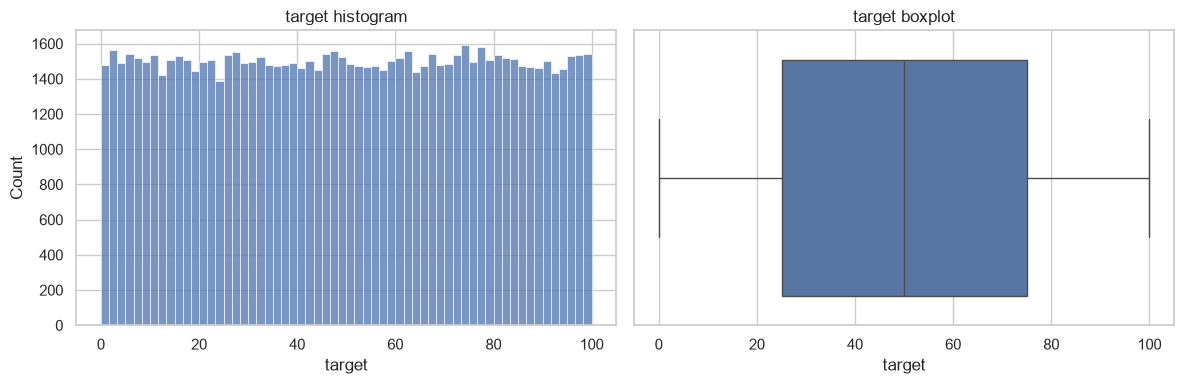

count    90000.000000
mean        50.033981
std         28.897243
min          0.002634
25%         25.091903
50%         50.030705
75%         75.059454
max         99.999482
Name: target, dtype: float64

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train["target"], bins=60, ax=axes[0])
axes[0].set_title("target histogram")
sns.boxplot(x=train["target"], ax=axes[1])
axes[1].set_title("target boxplot")
plt.tight_layout(); plt.show()
train["target"].describe()

The target is almost uniform on `[0, 100]` — a strong hint that the data is synthetic.
No outliers, no skew, so no target transformation is needed and plain RMSE is a sensible loss.

## 3. Feature distributions

In [5]:
summary = train.describe().T[["mean", "std", "min", "max"]]
summary["nunique"] = train.nunique()
summary["dtype"] = train.dtypes
summary

,mean,std,min,max,nunique,dtype
0,249.423944,144.336393,0.000000,499.000000,500,int64
1,250.236267,144.022200,0.000000,499.000000,500,int64
2,248.637289,144.107577,0.000000,499.000000,500,int64
3,249.736600,144.284945,0.000000,499.000000,500,int64
4,249.436178,143.941581,0.000000,499.000000,500,int64
5,249.656167,144.329168,0.000000,499.000000,500,int64
6,-0.011402,7.038171,-9.949874,9.949874,199,float64
7,0.498548,0.288682,0.000014,0.999987,90000,float64
8,0.499189,0.500002,0.000000,1.000000,2,int64
9,249.842033,144.612718,0.000000,499.000000,500,int64


In [6]:
# Group features by their value range — the anonymised columns fall into a few clear families.
feat_cols = [c for c in train.columns if c != "target"]
groups = {}
for c in feat_cols:
    key = (round(train[c].min(), 1), round(train[c].max(), 1), str(train[c].dtype))
    groups.setdefault(key, []).append(c)
for (lo, hi, dt), cols in sorted(groups.items(), key=lambda kv: -len(kv[1])):
    print(f"range [{lo}, {hi}] {dt:8s} -> {len(cols):2d} features: {cols}")

range [0.0, 15.0] float64  -> 40 features: ['13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '50', '51', '52']
range [0, 499] int64    -> 10 features: ['0', '1', '2', '3', '4', '5', '9', '10', '11', '12']
range [-9.9, 9.9] float64  ->  1 features: ['6']
range [0.0, 1.0] float64  ->  1 features: ['7']
range [0, 1] int64    ->  1 features: ['8']


Four families of features:

| family | columns | description |
|---|---|---|
| integers 0..499 | `0`–`5`, `9`–`12` (10 cols) | uniform integers |
| floats 0..15 | `13`–`52` (40 cols) | uniform floats |
| `6` | float, ±9.95, only 199 distinct values | looks like a discrete grid |
| `7` | float, uniform on [0, 1] | |
| `8` | integer 0/1 | binary flag |

Columns `6`, `7`, `8` are the odd ones out — worth a closer look.

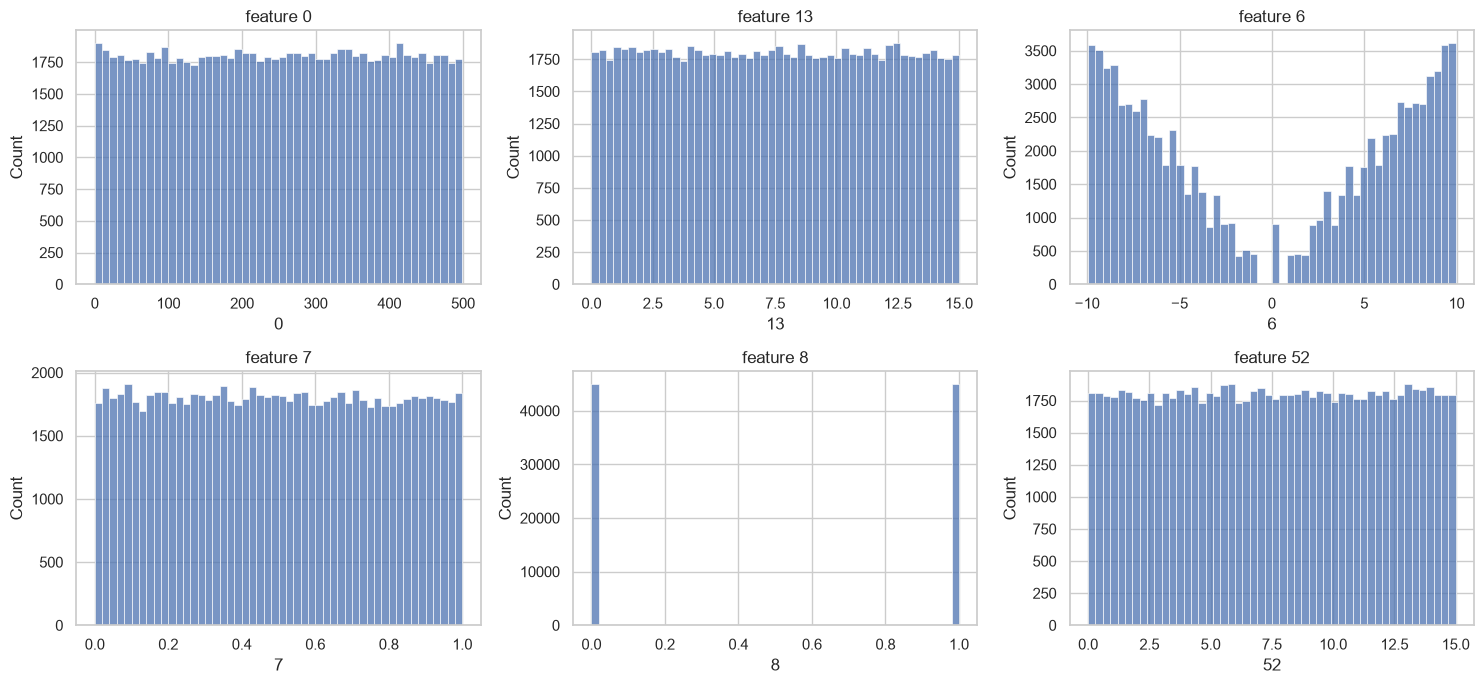

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), ["0", "13", "6", "7", "8", "52"]):
    sns.histplot(train[c], bins=50, ax=ax)
    ax.set_title(f"feature {c}")
plt.tight_layout(); plt.show()

## 4. Linear correlations

Top |corr| with target:
7     0.0121
40   -0.0072
26    0.0064
39    0.0063
35   -0.0063
1    -0.0055
50   -0.0052
31    0.0051
Name: target, dtype: float64


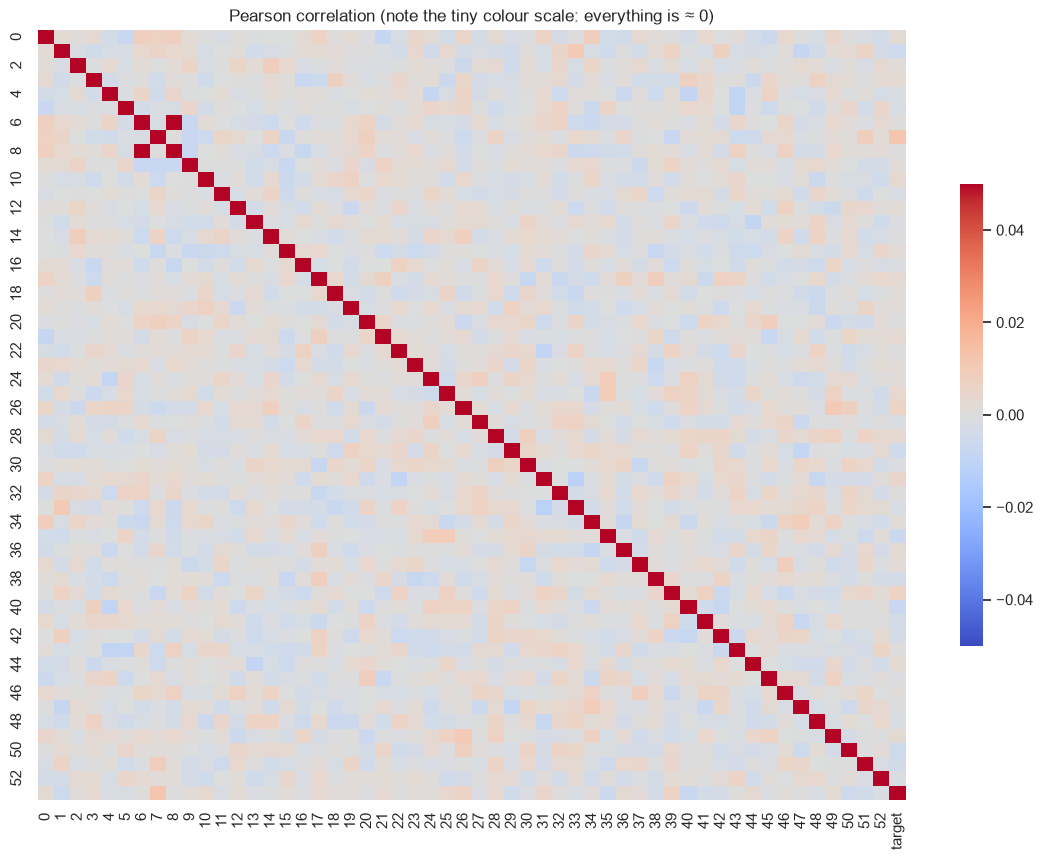

In [8]:
corr = train.corr(numeric_only=True)
target_corr = corr["target"].drop("target").sort_values(key=np.abs, ascending=False)
print("Top |corr| with target:")
print(target_corr.head(8).round(4))

plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-0.05, vmax=0.05, cbar_kws={"shrink": 0.6})
plt.title("Pearson correlation (note the tiny colour scale: everything is ≈ 0)")
plt.show()

**Every** linear correlation with the target is below 0.013 in absolute value, and features are
uncorrelated with each other. A linear model on the raw features would be useless (R² ≈ 0).
That does **not** mean the features carry no information — it means the relationship is non-linear.

## 5. Model-based feature importance

Quick LightGBM, all 53 features, hold-out RMSE: 0.0148


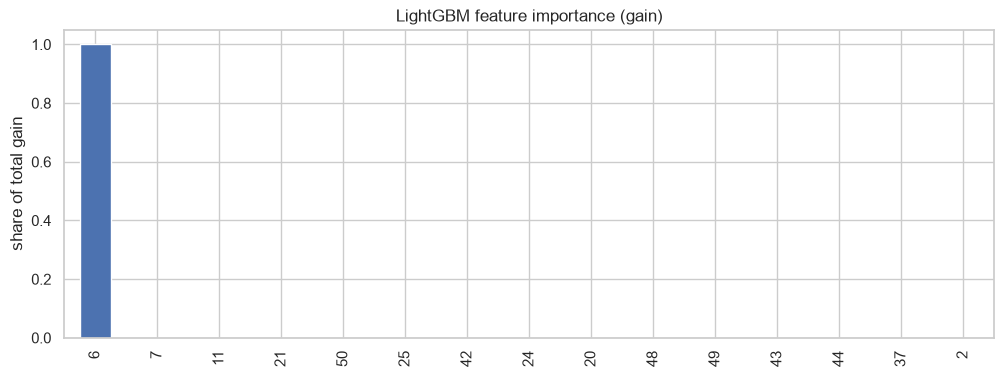

6     0.9999
7     0.0001
11    0.0000
21    0.0000
50    0.0000
dtype: float64

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import lightgbm as lgb

def rmse(y, p):
    return float(np.sqrt(mean_squared_error(y, p)))

X = train[feat_cols]
y = train["target"]
X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

gbm_quick = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.1, random_state=RANDOM_STATE, verbose=-1)
gbm_quick.fit(X_tr, y_tr)
print("Quick LightGBM, all 53 features, hold-out RMSE:", round(rmse(y_va, gbm_quick.predict(X_va)), 4))

imp = pd.Series(gbm_quick.booster_.feature_importance("gain"), index=feat_cols).sort_values(ascending=False)
imp = imp / imp.sum()
plt.figure(figsize=(12, 4))
imp.head(15).plot.bar()
plt.ylabel("share of total gain"); plt.title("LightGBM feature importance (gain)")
plt.show()
imp.head(5).round(4)

A tree model has no trouble: it immediately finds that feature `6` explains almost all of the
variance and feature `7` contributes the remainder. Everything else is noise.

## 6. Finding the functional form

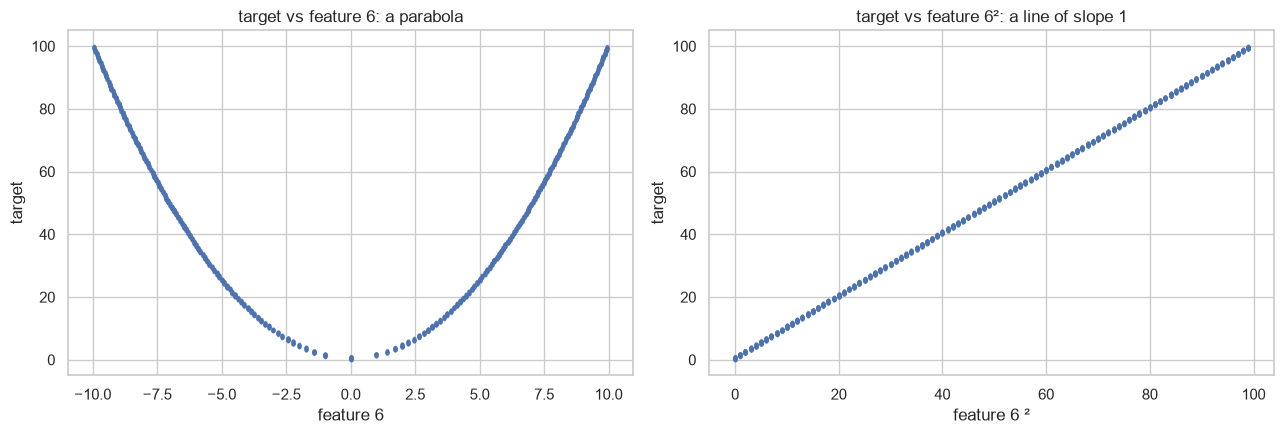

corr(target, 6²) = 0.99995


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sample = train.sample(5000, random_state=RANDOM_STATE)
axes[0].scatter(sample["6"], sample["target"], s=3, alpha=0.4)
axes[0].set_xlabel("feature 6"); axes[0].set_ylabel("target"); axes[0].set_title("target vs feature 6: a parabola")
axes[1].scatter(sample["6"] ** 2, sample["target"], s=3, alpha=0.4)
axes[1].set_xlabel("feature 6 ²"); axes[1].set_ylabel("target"); axes[1].set_title("target vs feature 6²: a line of slope 1")
plt.tight_layout(); plt.show()
print("corr(target, 6²) =", round(np.corrcoef(train["target"], train["6"] ** 2)[0, 1], 6))

The target is a parabola in feature `6` — this is why the *linear* correlation was zero
(symmetric function of a symmetric variable). Squaring the feature gives an almost perfect line.
The remaining vertical spread is about 1 unit; let's look at the residual.

residual: min 0.0000  max 1.0000  mean 0.4985  std 0.2887

Top |corr| of residual with features:
7     1.0000
51    0.0084
20    0.0077
9    -0.0072
0     0.0072
dtype: float64


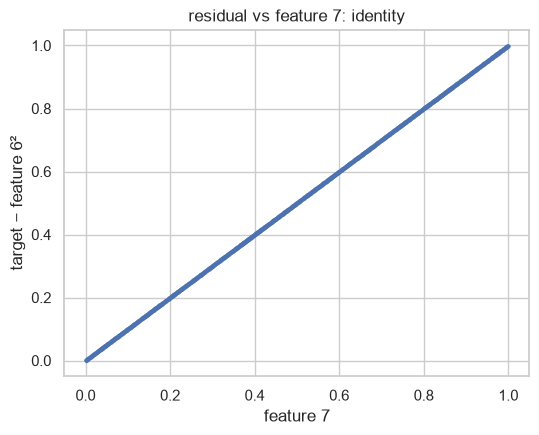

In [11]:
residual = train["target"] - train["6"] ** 2
print("residual: min %.4f  max %.4f  mean %.4f  std %.4f" % (residual.min(), residual.max(), residual.mean(), residual.std()))

res_corr = pd.Series({c: np.corrcoef(residual, train[c])[0, 1] for c in feat_cols}).sort_values(key=np.abs, ascending=False)
print("\nTop |corr| of residual with features:")
print(res_corr.head(5).round(4))

plt.figure(figsize=(6, 4.5))
plt.scatter(sample["7"], residual.loc[sample.index], s=3, alpha=0.4)
plt.xlabel("feature 7"); plt.ylabel("target − feature 6²"); plt.title("residual vs feature 7: identity")
plt.show()

The residual lives in `[0, 1]` and is **exactly** feature `7` (correlation 1.0000).
So the generating formula is

$$\text{target} = x_6^2 + x_7$$

## 7. Verifying the formula and comparing models

In [12]:
formula = train["6"] ** 2 + train["7"]
print("RMSE of the closed-form formula on train: %.3g" % rmse(train["target"], formula))
print("max |error|: %.3g" % (train["target"] - formula).abs().max())

RMSE of the closed-form formula on train: 9.69e-15
max |error|: 5.68e-14


In [13]:
from sklearn.linear_model import LinearRegression

def engineered(df):
    return pd.DataFrame({"f6_squared": df["6"] ** 2, "f7": df["7"]})

lin = LinearRegression().fit(engineered(X_tr), y_tr)
print("Linear regression on [6², 7]  hold-out RMSE: %.3g" % rmse(y_va, lin.predict(engineered(X_va))))
print("coefficients:", lin.coef_.round(6), " intercept:", round(lin.intercept_, 6))

# No column subsampling: with 51 noise features, randomly dropping `6` or `7` from a tree is costly.
gbm = lgb.LGBMRegressor(n_estimators=1500, learning_rate=0.05, num_leaves=31, random_state=RANDOM_STATE, verbose=-1)
gbm.fit(X_tr, y_tr)
print("LightGBM on all raw features   hold-out RMSE: %.4f" % rmse(y_va, gbm.predict(X_va)))

gbm_eng = lgb.LGBMRegressor(n_estimators=1500, learning_rate=0.05, random_state=RANDOM_STATE, verbose=-1)
gbm_eng.fit(engineered(X_tr), y_tr)
print("LightGBM on [6², 7]            hold-out RMSE: %.4f" % rmse(y_va, gbm_eng.predict(engineered(X_va))))

Linear regression on [6², 7]  hold-out RMSE: 1.22e-13
coefficients: [1. 1.]  intercept: 0.0


LightGBM on all raw features   hold-out RMSE: 0.0093


LightGBM on [6², 7]            hold-out RMSE: 0.0047


| model | inputs | hold-out RMSE |
|---|---|---|
| Linear regression | `6²`, `7` | ≈ 1e-13 (machine precision) |
| LightGBM | `6²`, `7` | ~0.005 |
| LightGBM | all 53 raw features | ~0.01 |

Gradient boosting is a strong generic baseline but it approximates a smooth surface with
piecewise-constant steps, so it can never be exact. Once the functional form is known, a
two-feature linear model is both the simplest and the most accurate option.

## 8. Conclusions

* The dataset is synthetic: `target = feature_6² + feature_7`, all other 51 features are noise.
* Linear correlations are ≈ 0 because the dependence is quadratic and symmetric — tree-based
  importance and scatter plots reveal it immediately.
* **Final model:** `LinearRegression` on the engineered features `[6², 7]`
  (`train.py --model linear`, the default). Cross-validated RMSE ≈ 1e-13.
* **Baseline kept for comparison:** `LightGBM` on all raw features (`train.py --model lgbm`), CV RMSE ≈ 0.009.
* The engineered features live in `features.py` and are shared by `train.py` and `predict.py`,
  so inference is guaranteed to use the same transformation as training.
* Caveat: this exact relationship holds for the provided data. If the hidden test were generated
  differently, the linear model would degrade gracefully only within the same functional family;
  the LightGBM model is the more robust fallback.